In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

# Plot 1

Graph fraction of particles versus angular frequency

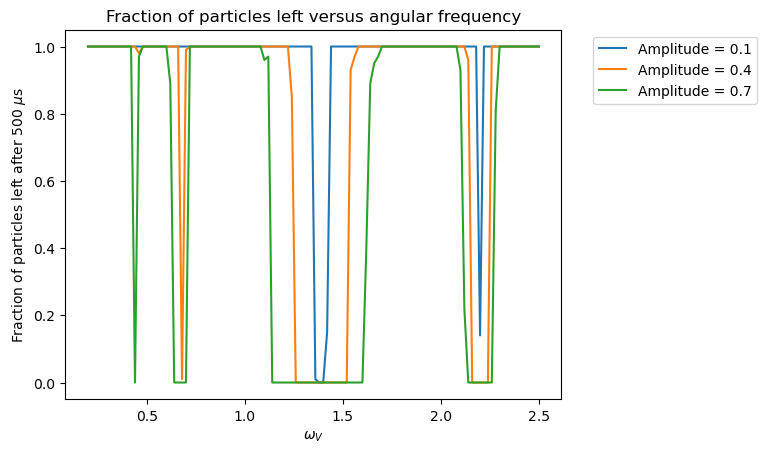

In [3]:
data_01 = pd.read_csv('../Project3_Outputs/100_particles_f0.1.csv')
data_04 = pd.read_csv('../Project3_Outputs/100_particles_f0.4.csv')
data_07 = pd.read_csv('../Project3_Outputs/100_particles_f0.7.csv')

plt.plot(data_01['frequency'], data_01['trapped']/100, label='Amplitude = 0.1')
plt.plot(data_04['frequency'], data_04['trapped']/100, label='Amplitude = 0.4')
plt.plot(data_07['frequency'], data_07['trapped']/100, label='Amplitude = 0.7')
plt.title('Fraction of particles left versus angular frequency')
plt.xlabel(r'$\omega _V$')
plt.ylabel(r'Fraction of particles left after 500 $\mu$s')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('../Figures/Fraction left vs frequency.pdf', bbox_inches='tight')

I see that a higher amplitude will 'deepen' the wells in the plot

The dips correspond to the resonance --> this is also shown in my book (page 57, figure 3.4)

Also from this paper: drives the undamped harmonic oscillator for z1(t) on resonance,eventually leading to a linear growth of the amplitude of z1(t) --> a.k.a. particles go vooom out of there (https://arxiv.org/pdf/1305.4861)

# Plot 2

Zooming in on a resonance frequency, and plotting with/without Coulomb interactions

Try 5 runs per thingy with different seed each time.

Let's zoom in on 0.66 MHz, that's a nice and clear well but not too big (therefore not too demanding for a scan)

Scan in steps of 0.002 from 0.55 to 0.75 so I can catch any shifts, which I think might happen with CI on!

Grid is 10x smaller, should be fine. Total number of frequencies I scan is ~what it was before so should be okay time-wise

In [4]:
print(data_07[data_07['trapped']==0])
print(data_07.to_string())

     frequency  trapped
12        0.44        0
22        0.64        0
23        0.66        0
24        0.68        0
25        0.70        0
47        1.14        0
48        1.16        0
49        1.18        0
50        1.20        0
51        1.22        0
52        1.24        0
53        1.26        0
54        1.28        0
55        1.30        0
56        1.32        0
57        1.34        0
58        1.36        0
59        1.38        0
60        1.40        0
61        1.42        0
62        1.44        0
63        1.46        0
64        1.48        0
65        1.50        0
66        1.52        0
67        1.54        0
68        1.56        0
69        1.58        0
70        1.60        0
97        2.14        0
98        2.16        0
99        2.18        0
100       2.20        0
101       2.22        0
102       2.24        0
103       2.26        0
     frequency  trapped
0         0.20      100
1         0.22      100
2         0.24      100
3         0.26  

In [5]:
data_without = np.zeros(101)
data_with = np.zeros(101)

#Read in all and take average
for i in range(1, 6, 1):
    data = pd.read_csv(rf'../Project3_Outputs/100_particles_noCI_freqscan{i}.csv')
    if i == 1:
        freqs = data['frequency']
    data_without += 0.2*data['trapped'].to_numpy()

#Repeat for with interactions
for i in range(1, 6, 1):
    data = pd.read_csv(rf'../Project3_Outputs/100_particles_withCI_freqscan{i}.csv')
    data_with += 0.2*data['trapped'].to_numpy()


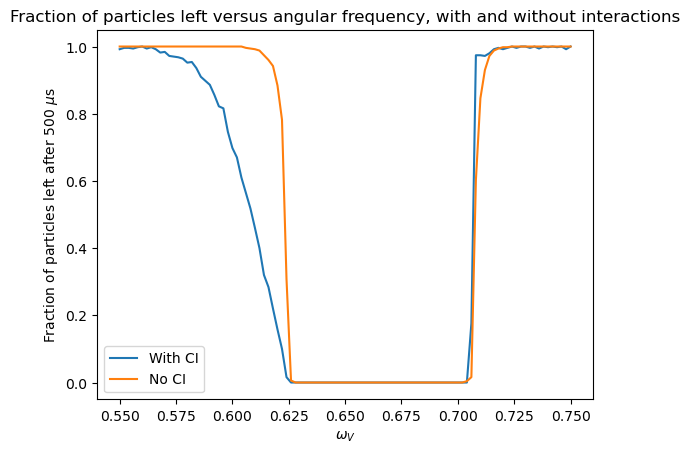

In [7]:
plt.plot(freqs, data_with/100, label='With CI')
plt.plot(freqs, data_without/100, label = 'No CI')
plt.title('Fraction of particles left versus angular frequency, with and without interactions')
plt.xlabel(r'$\omega _V$')
plt.ylabel(r'Fraction of particles left after 500 $\mu$s')
plt.legend()
plt.savefig('../Figures/Fraction left vs frequency, with vs without interactions.pdf', bbox_inches='tight')